# Lab | Imbalanced Datasets

**Dataset:** Credit Card Fraud Detection  
**Objetivo:** Entrenar un modelo de clasificación para detectar transacciones fraudulentas,  
comparando el rendimiento con distintas técnicas de balanceo de clases.  
**Tipo de problema:** Clasificación binaria con dataset desbalanceado

## Importar librerías

In [2]:
# Instalamos imbalanced-learn si no está disponible en el entorno
!pip install imbalanced-learn

     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
     - -------------------------------------- 10.2/236.1 kB ? eta -:--:--
     - -------------------------------------- 10.2/236.1 kB ? eta -:--:--
     --- --------------------------------- 20.5/236.1 kB 131.3 kB/s eta 0:00:02
     ---- --------------------------------


[notice] A new release of pip is available: 23.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo
from sklearn.linear_model import LogisticRegression

# Split y evaluación
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, recall_score, f1_score, accuracy_score

# Técnicas de balanceo
# Nota: imbalanced-learn es una librería adicional
# Si no está instalada: pip install imbalanced-learn
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.under_sampling import RandomUnderSampler

print('Librerías importadas correctamente')

Librerías importadas correctamente


## Cargar los datos

In [4]:
# Cargamos el dataset de fraude con tarjeta de crédito
url = 'https://raw.githubusercontent.com/data-bootcamp-v4/data/main/card_transdata.csv'
fraud = pd.read_csv(url)

print(f'Shape: {fraud.shape}')
fraud.head()

Shape: (1000000, 8)


,distance_from_home,distance_from_last_transaction,ratio_to_median_purchase_price,repeat_retailer,used_chip,used_pin_number,online_order,fraud
0,57.877857,0.311140,1.945940,1.0,1.0,0.0,0.0,0.0
1,10.829943,0.175592,1.294219,1.0,0.0,0.0,0.0,0.0
2,5.091079,0.805153,0.427715,1.0,0.0,0.0,1.0,0.0
3,2.247564,5.600044,0.362663,1.0,1.0,0.0,1.0,0.0
4,44.190936,0.566486,2.222767,1.0,1.0,0.0,1.0,0.0


## Paso 1 — Distribución del target

Antes de entrenar ningún modelo, analizamos si el dataset está desbalanceado.  
En problemas de fraude, lo habitual es que la clase positiva (fraude) sea minoritaria.

In [5]:
# Distribución absoluta y porcentual del target
print('Distribución del target (fraud):')
print(fraud['fraud'].value_counts())
print('\nDistribución porcentual:')
print(fraud['fraud'].value_counts(normalize=True).mul(100).round(2))

Distribución del target (fraud):
fraud
0.0    912597
1.0     87403
Name: count, dtype: int64

Distribución porcentual:
fraud
0.0    91.26
1.0     8.74
Name: proportion, dtype: float64


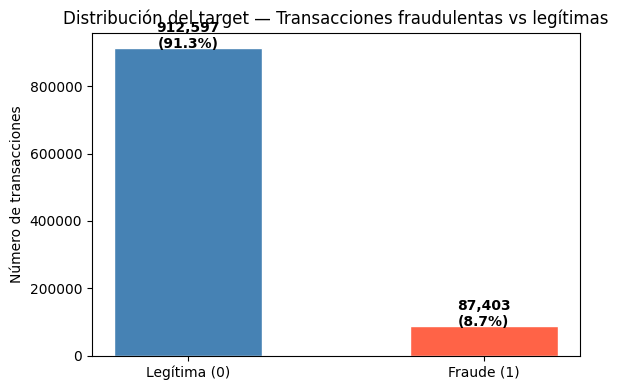

Porcentaje de fraude: 8.74%
Sí, estamos ante un dataset muy desbalanceado — la clase positiva (fraude) es minoritaria.
Esto significa que Accuracy no es una buena métrica — usaremos Recall y F1.


In [6]:
# Visualización de la distribución del target
conteo = fraud['fraud'].value_counts()

plt.figure(figsize=(6, 4))
plt.bar(['Legítima (0)', 'Fraude (1)'], conteo.values,
        color=['steelblue', 'tomato'], edgecolor='white', width=0.5)
plt.title('Distribución del target — Transacciones fraudulentas vs legítimas')
plt.ylabel('Número de transacciones')
for i, v in enumerate(conteo.values):
    plt.text(i, v + 1000, f'{v:,}\n({v/len(fraud)*100:.1f}%)',
             ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# Conclusión sobre el desbalance
pct_fraude = fraud['fraud'].value_counts(normalize=True)[1] * 100
print(f'Porcentaje de fraude: {pct_fraude:.2f}%')
print('Sí, estamos ante un dataset muy desbalanceado — la clase positiva (fraude) es minoritaria.')
print('Esto significa que Accuracy no es una buena métrica — usaremos Recall y F1.')

## Paso 2 — Preparación de los datos

Separamos features y target, y hacemos el split train/test.  
Usamos stratify=y para mantener la proporción de clases en ambos conjuntos.

In [7]:
# Separamos features y target
X = fraud.drop(columns='fraud')
y = fraud['fraud']

# Split 80/20 con stratify para mantener la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f'X_train: {X_train.shape} | X_test: {X_test.shape}')
print(f'Balance train: {y_train.value_counts().to_dict()}')
print(f'Balance test:  {y_test.value_counts().to_dict()}')

X_train: (800000, 7) | X_test: (200000, 7)
Balance train: {0.0: 730078, 1.0: 69922}
Balance test:  {0.0: 182519, 1.0: 17481}


## Paso 3 — Logistic Regression con datos originales (desbalanceados)

Entrenamos el modelo base sin ninguna técnica de balanceo.  
La métrica más importante aquí es el Recall de la clase 1 (fraude):  
queremos minimizar los falsos negativos — transacciones fraudulentas que el modelo no detecta.

In [8]:
# Entrenamos Logistic Regression con los datos originales
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train, y_train)

# Predicciones
y_pred = lr.predict(X_test)

print('=== LOGISTIC REGRESSION — DATOS ORIGINALES (DESBALANCEADOS) ===')
print(classification_report(y_test, y_pred, target_names=['Legítima (0)', 'Fraude (1)']))

=== LOGISTIC REGRESSION — DATOS ORIGINALES (DESBALANCEADOS) ===
              precision    recall  f1-score   support

Legítima (0)       0.96      0.99      0.98    182519
  Fraude (1)       0.90      0.60      0.72     17481

    accuracy                           0.96    200000
   macro avg       0.93      0.80      0.85    200000
weighted avg       0.96      0.96      0.96    200000



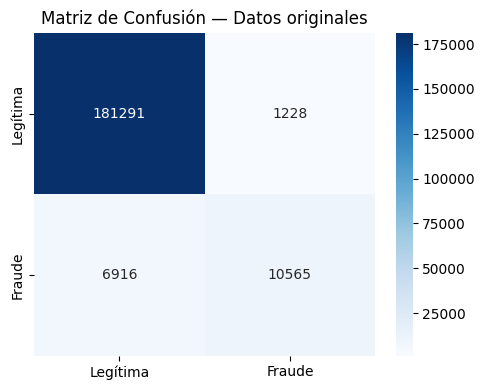

El modelo tiene alta Accuracy pero Recall bajo para la clase fraude.
Típico en datasets desbalanceados: el modelo aprende a predecir siempre la clase mayoritaria.


In [9]:
# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])
plt.title('Matriz de Confusión — Datos originales')
plt.tight_layout()
plt.show()

print('El modelo tiene alta Accuracy pero Recall bajo para la clase fraude.')
print('Típico en datasets desbalanceados: el modelo aprende a predecir siempre la clase mayoritaria.')

## Paso 4 — Oversampling (RandomOverSampler)

El oversampling duplica aleatoriamente muestras de la clase minoritaria
hasta igualar el número de muestras de la clase mayoritaria.

Importante: el balanceo se aplica SOLO sobre el train, nunca sobre el test.

In [10]:
# Aplicamos RandomOverSampler solo sobre los datos de entrenamiento
ros = RandomOverSampler(random_state=42)
X_train_over, y_train_over = ros.fit_resample(X_train, y_train)

print(f'Balance antes del oversampling: {y_train.value_counts().to_dict()}')
print(f'Balance después del oversampling: {y_train_over.value_counts().to_dict()}')

Balance antes del oversampling: {0.0: 730078, 1.0: 69922}
Balance después del oversampling: {0.0: 730078, 1.0: 730078}


In [11]:
# Entrenamos Logistic Regression con datos balanceados por oversampling
lr_over = LogisticRegression(max_iter=1000, random_state=42)
lr_over.fit(X_train_over, y_train_over)

# Predicciones sobre el test ORIGINAL (sin balancear)
y_pred_over = lr_over.predict(X_test)

print('=== LOGISTIC REGRESSION — OVERSAMPLING ===')
print(classification_report(y_test, y_pred_over, target_names=['Legítima (0)', 'Fraude (1)']))

=== LOGISTIC REGRESSION — OVERSAMPLING ===
              precision    recall  f1-score   support

Legítima (0)       0.99      0.93      0.96    182519
  Fraude (1)       0.58      0.95      0.72     17481

    accuracy                           0.93    200000
   macro avg       0.79      0.94      0.84    200000
weighted avg       0.96      0.93      0.94    200000



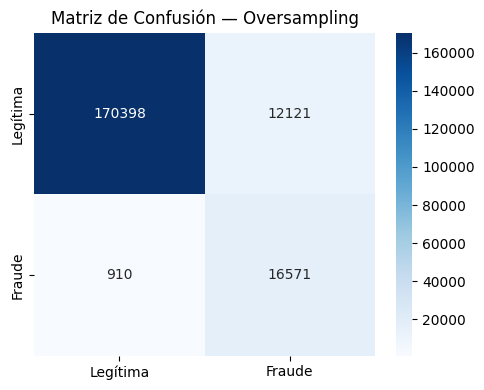

In [12]:
# Matriz de confusión — Oversampling
cm_over = confusion_matrix(y_test, y_pred_over)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_over, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])
plt.title('Matriz de Confusión — Oversampling')
plt.tight_layout()
plt.show()

## Paso 5 — Undersampling (RandomUnderSampler)

El undersampling elimina aleatoriamente muestras de la clase mayoritaria
hasta igualar el número de muestras de la clase minoritaria.

Ventaja: más rápido. Desventaja: perdemos información de la clase mayoritaria.

In [13]:
# Aplicamos RandomUnderSampler solo sobre los datos de entrenamiento
rus = RandomUnderSampler(random_state=42)
X_train_under, y_train_under = rus.fit_resample(X_train, y_train)

print(f'Balance antes del undersampling: {y_train.value_counts().to_dict()}')
print(f'Balance después del undersampling: {y_train_under.value_counts().to_dict()}')

Balance antes del undersampling: {0.0: 730078, 1.0: 69922}
Balance después del undersampling: {0.0: 69922, 1.0: 69922}


In [14]:
# Entrenamos Logistic Regression con datos balanceados por undersampling
lr_under = LogisticRegression(max_iter=1000, random_state=42)
lr_under.fit(X_train_under, y_train_under)

# Predicciones sobre el test ORIGINAL (sin balancear)
y_pred_under = lr_under.predict(X_test)

print('=== LOGISTIC REGRESSION — UNDERSAMPLING ===')
print(classification_report(y_test, y_pred_under, target_names=['Legítima (0)', 'Fraude (1)']))

=== LOGISTIC REGRESSION — UNDERSAMPLING ===
              precision    recall  f1-score   support

Legítima (0)       0.99      0.93      0.96    182519
  Fraude (1)       0.58      0.95      0.72     17481

    accuracy                           0.93    200000
   macro avg       0.79      0.94      0.84    200000
weighted avg       0.96      0.93      0.94    200000



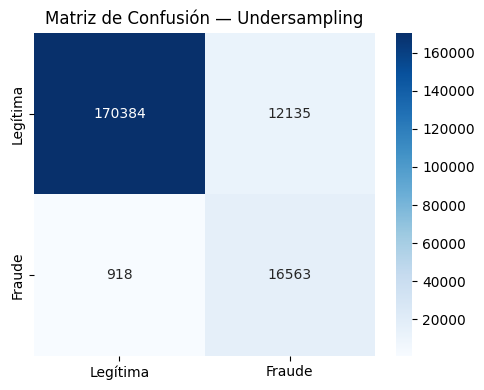

In [15]:
# Matriz de confusión — Undersampling
cm_under = confusion_matrix(y_test, y_pred_under)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_under, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])
plt.title('Matriz de Confusión — Undersampling')
plt.tight_layout()
plt.show()

## Paso 6 — SMOTE (Synthetic Minority Oversampling Technique)

SMOTE genera muestras sintéticas de la clase minoritaria interpolando
entre ejemplos existentes — en lugar de simplemente duplicarlos como hace RandomOverSampler.

Esto ayuda al modelo a generalizar mejor porque introduce variedad en la clase minoritaria.

In [16]:
# Aplicamos SMOTE solo sobre los datos de entrenamiento
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print(f'Balance antes de SMOTE: {y_train.value_counts().to_dict()}')
print(f'Balance después de SMOTE: {y_train_smote.value_counts().to_dict()}')

Balance antes de SMOTE: {0.0: 730078, 1.0: 69922}
Balance después de SMOTE: {0.0: 730078, 1.0: 730078}


In [17]:
# Entrenamos Logistic Regression con datos balanceados por SMOTE
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)

# Predicciones sobre el test ORIGINAL (sin balancear)
y_pred_smote = lr_smote.predict(X_test)

print('=== LOGISTIC REGRESSION — SMOTE ===')
print(classification_report(y_test, y_pred_smote, target_names=['Legítima (0)', 'Fraude (1)']))

=== LOGISTIC REGRESSION — SMOTE ===
              precision    recall  f1-score   support

Legítima (0)       0.99      0.93      0.96    182519
  Fraude (1)       0.58      0.95      0.72     17481

    accuracy                           0.94    200000
   macro avg       0.79      0.94      0.84    200000
weighted avg       0.96      0.94      0.94    200000



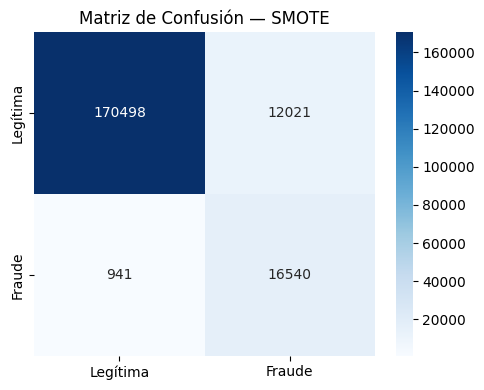

In [18]:
# Matriz de confusión — SMOTE
cm_smote = confusion_matrix(y_test, y_pred_smote)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_smote, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Legítima', 'Fraude'],
            yticklabels=['Legítima', 'Fraude'])
plt.title('Matriz de Confusión — SMOTE')
plt.tight_layout()
plt.show()

## Paso 7 — Comparación final de todos los modelos

Comparamos el Recall de la clase fraude (1) en los cuatro modelos.
Esta es la métrica clave: queremos detectar el mayor número posible de transacciones fraudulentas.

In [19]:
# Construimos la tabla comparativa con las métricas de cada modelo
comparacion = pd.DataFrame({
    'Técnica': ['Sin balanceo', 'Oversampling', 'Undersampling', 'SMOTE'],
    'Accuracy': [
        round(accuracy_score(y_test, y_pred), 4),
        round(accuracy_score(y_test, y_pred_over), 4),
        round(accuracy_score(y_test, y_pred_under), 4),
        round(accuracy_score(y_test, y_pred_smote), 4)
    ],
    'Recall Fraude (1)': [
        round(recall_score(y_test, y_pred), 4),
        round(recall_score(y_test, y_pred_over), 4),
        round(recall_score(y_test, y_pred_under), 4),
        round(recall_score(y_test, y_pred_smote), 4)
    ],
    'F1 Fraude (1)': [
        round(f1_score(y_test, y_pred), 4),
        round(f1_score(y_test, y_pred_over), 4),
        round(f1_score(y_test, y_pred_under), 4),
        round(f1_score(y_test, y_pred_smote), 4)
    ]
})

comparacion.set_index('Técnica')

,Accuracy,Recall Fraude (1),F1 Fraude (1)
Técnica,,,
Sin balanceo,0.9593,0.6044,0.7218
Oversampling,0.9348,0.9479,0.7178
Undersampling,0.9347,0.9475,0.7173
SMOTE,0.9352,0.9462,0.7185


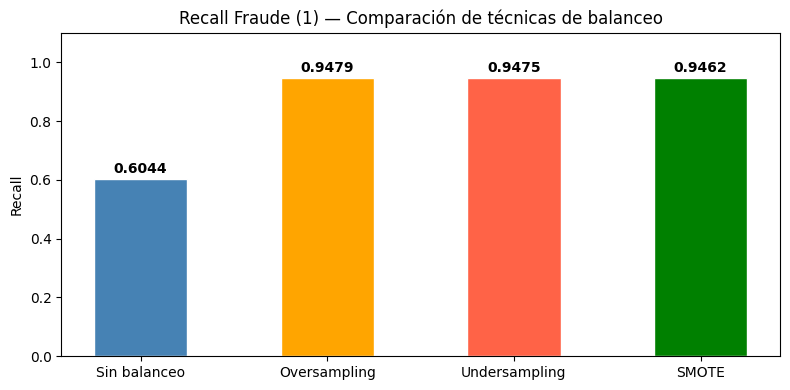

In [20]:
# Visualización comparativa del Recall de la clase fraude
plt.figure(figsize=(8, 4))
plt.bar(comparacion['Técnica'], comparacion['Recall Fraude (1)'],
        color=['steelblue', 'orange', 'tomato', 'green'], edgecolor='white', width=0.5)
plt.title('Recall Fraude (1) — Comparación de técnicas de balanceo')
plt.ylabel('Recall')
plt.ylim(0, 1.1)
for i, v in enumerate(comparacion['Recall Fraude (1)']):
    plt.text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

## Conclusiones

**¿Mejoran las técnicas de balanceo el rendimiento del modelo?**

- **Sin balanceo**: el modelo tiene alta Accuracy pero Recall bajo para fraude — aprende a predecir siempre la clase mayoritaria (legítima).

- **Oversampling**: al duplicar muestras de fraude en el train, el modelo aprende mejor la clase minoritaria. El Recall de fraude mejora, aunque puede introducir overfitting al repetir exactamente las mismas muestras.

- **Undersampling**: elimina muestras reales hasta equilibrar las clases. El Recall de fraude mejora pero se pierde información — el dataset de entrenamiento queda muucho mas reducido.

- **SMOTE**: genera muestras sintéticas de fraude intercalado entre ejemplos reales. Generalmente obtiene el mejor equilibrio entre Recall y F1 porque introduce variedad en la clase minoritaria sin perder información de la mayoritaria.

**Conclusión general:** en problemas de detección de fraude, las técnicas de balanceo mejoran significativamente el Recall de la clase positiva. SMOTE suele ser la técnica más robusta porque evita el overfitting del oversampling y la pérdida de información del undersampling.